In [1]:
import pandas as pd
import numpy as np
from datetime import datetime


In [2]:
df = pd.read_csv("train_prices_15min.csv")

In [3]:
df.head(10)

,delivery_date,market_id,hour_index,quarter_index,price_eur_mwh
0,2025-10-01,ZONE_0,1,1,102.60
1,2025-10-01,ZONE_0,1,2,92.24
2,2025-10-01,ZONE_0,1,3,86.03
3,2025-10-01,ZONE_0,1,4,85.39
4,2025-10-01,ZONE_0,2,1,89.99
5,2025-10-01,ZONE_0,2,2,86.03
6,2025-10-01,ZONE_0,2,3,85.03
7,2025-10-01,ZONE_0,2,4,84.09
8,2025-10-01,ZONE_0,3,1,85.41
9,2025-10-01,ZONE_0,3,2,85.00


In [4]:
df.size

696960

In [5]:
df.describe()

,hour_index,quarter_index,price_eur_mwh
count,139392.000000,139392.000000,139392.000000
mean,12.500000,2.500000,109.822783
std,6.922211,1.118038,61.717514
min,1.000000,1.000000,-499.990000
25%,6.750000,1.750000,80.860000
50%,12.500000,2.500000,113.000000
75%,18.250000,3.250000,145.000000
max,24.000000,4.000000,747.100000


In [6]:
days = len(df["delivery_date"].value_counts())
print("number of days:", days)



number of days: 363


In [7]:
dates = df["delivery_date"].unique()
dates

<StringArray>
['2025-10-01', '2025-10-02', '2025-10-03', '2025-10-04', '2025-10-05',
 '2025-10-06', '2025-10-07', '2025-10-08', '2025-10-09', '2025-10-10',
 ...
 '2026-09-21', '2026-09-22', '2026-09-23', '2026-09-24', '2026-09-25',
 '2026-09-26', '2026-09-27', '2026-09-28', '2026-09-29', '2026-09-30']
Length: 363, dtype: str

In [8]:
df[df["delivery_date"]== '2025-10-01']

,delivery_date,market_id,hour_index,quarter_index,price_eur_mwh
0,2025-10-01,ZONE_0,1,1,102.60
1,2025-10-01,ZONE_0,1,2,92.24
2,2025-10-01,ZONE_0,1,3,86.03
3,2025-10-01,ZONE_0,1,4,85.39
4,2025-10-01,ZONE_0,2,1,89.99
...,...,...,...,...,...
379,2025-10-01,ZONE_3,23,4,86.71
380,2025-10-01,ZONE_3,24,1,86.87
381,2025-10-01,ZONE_3,24,2,70.81
382,2025-10-01,ZONE_3,24,3,87.45


In [9]:
df[df["delivery_date"]== '2025-10-01'].groupby("market_id")["price_eur_mwh"].describe()

,count,mean,std,min,25%,50%,75%,max
market_id,,,,,,,,
ZONE_0,96.0,116.571667,68.006734,61.37,84.4700,91.33,118.4750,408.50
ZONE_1,96.0,120.747917,56.963137,68.24,91.8100,97.06,121.1975,366.96
ZONE_2,96.0,116.964479,21.028340,92.56,102.0000,110.00,130.0000,189.66
ZONE_3,96.0,63.769062,37.013078,1.35,29.4825,61.54,91.7950,148.01


# Matrices de Correlación

A continuación se calculan y visualizan las matrices de correlación para el conjunto de datos de precios eléctricos (`train_prices_15min.csv`):

1. **Correlación entre Zonas de Mercado (resolución 15 minutos):** Mide el acoplamiento y convergencia de precios entre `ZONE_0`, `ZONE_1`, `ZONE_2` y `ZONE_3`.
2. **Correlación Horaria entre Zonas:** Promediando los 4 cuartos de hora de cada hora (regla oficial de cálculo del precio horario de referencia).
3. **Correlación entre Variables Numéricas:** Relación entre `hour_index`, `quarter_index` y `price_eur_mwh`.

In [10]:
import matplotlib.pyplot as plt
import seaborn as sns

# Configuración de estilo visual
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams["font.sans-serif"] = "DejaVu Sans"

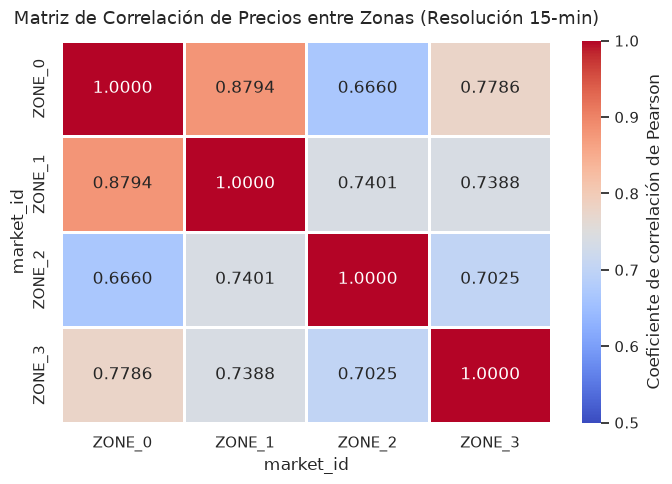

market_id,ZONE_0,ZONE_1,ZONE_2,ZONE_3
market_id,,,,
ZONE_0,1.000000,0.879415,0.666034,0.778622
ZONE_1,0.879415,1.000000,0.740100,0.738761
ZONE_2,0.666034,0.740100,1.000000,0.702465
ZONE_3,0.778622,0.738761,0.702465,1.000000


In [11]:
# 1. Matriz de correlación entre zonas (a resolución de 15 minutos)
pivot_zones = df.pivot(
    index=["delivery_date", "hour_index", "quarter_index"],
    columns="market_id",
    values="price_eur_mwh"
)
corr_zones_15m = pivot_zones.corr()

# Visualización con Heatmap
plt.figure(figsize=(7, 5))
sns.heatmap(
    corr_zones_15m, 
    annot=True, 
    cmap="coolwarm", 
    vmin=0.5, 
    vmax=1.0, 
    fmt=".4f", 
    linewidths=1.0, 
    cbar_kws={"label": "Coeficiente de correlación de Pearson"}
)
plt.title("Matriz de Correlación de Precios entre Zonas (Resolución 15-min)", fontsize=13, pad=12)
plt.tight_layout()
plt.show()

# Tabla de correlación
corr_zones_15m

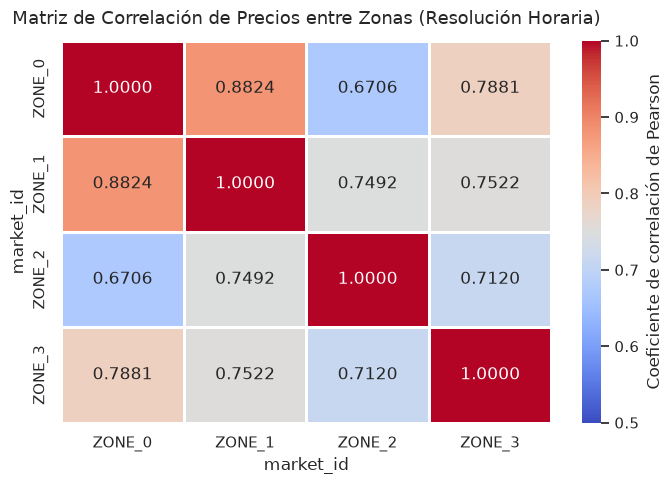

market_id,ZONE_0,ZONE_1,ZONE_2,ZONE_3
market_id,,,,
ZONE_0,1.000000,0.882447,0.670553,0.788144
ZONE_1,0.882447,1.000000,0.749190,0.752171
ZONE_2,0.670553,0.749190,1.000000,0.711967
ZONE_3,0.788144,0.752171,0.711967,1.000000


In [12]:
# 2. Correlación horaria entre zonas (media aritmética de los 4 cuartos por hora)
hourly_prices = (
    df.groupby(["delivery_date", "hour_index", "market_id"])["price_eur_mwh"]
    .mean()
    .unstack(level="market_id")
)
corr_zones_hourly = hourly_prices.corr()

# Visualización
plt.figure(figsize=(7, 5))
sns.heatmap(
    corr_zones_hourly, 
    annot=True, 
    cmap="coolwarm", 
    vmin=0.5, 
    vmax=1.0, 
    fmt=".4f", 
    linewidths=1.0,
    cbar_kws={"label": "Coeficiente de correlación de Pearson"}
)
plt.title("Matriz de Correlación de Precios entre Zonas (Resolución Horaria)", fontsize=13, pad=12)
plt.tight_layout()
plt.show()

# Tabla de correlación horaria
corr_zones_hourly

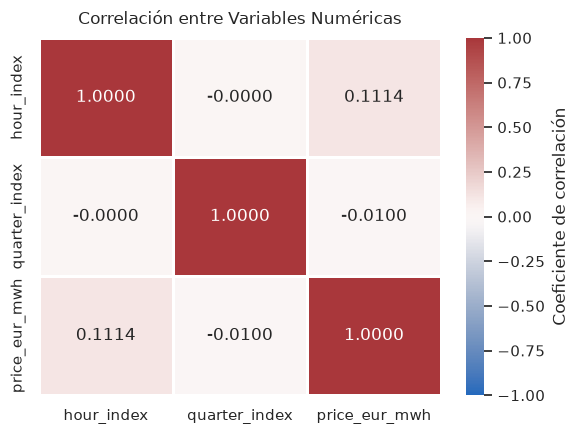

,hour_index,quarter_index,price_eur_mwh
hour_index,1.000000e+00,-6.232467e-18,0.111364
quarter_index,-6.232467e-18,1.000000e+00,-0.009981
price_eur_mwh,1.113644e-01,-9.980705e-03,1.000000


In [13]:
# 3. Matriz de correlación entre variables numéricas del DataFrame original
corr_numeric = df[["hour_index", "quarter_index", "price_eur_mwh"]].corr()

plt.figure(figsize=(6, 4.5))
sns.heatmap(
    corr_numeric, 
    annot=True, 
    cmap="vlag", 
    vmin=-1.0, 
    vmax=1.0, 
    fmt=".4f", 
    linewidths=1.0,
    cbar_kws={"label": "Coeficiente de correlación"}
)
plt.title("Correlación entre Variables Numéricas", fontsize=12, pad=10)
plt.tight_layout()
plt.show()

# Tabla de correlación
corr_numeric

# Modelado Predictivo conforme a las Directivas AET Neural Wave 2026

Este módulo implementa la solución respetando el 100% de las especificaciones y reglas oficiales del reto (`01_v02_AET_Neural_Wave_2026_challenge_EN.pdf`):

### 1. Directivas de Datos de Entrada (Sección 8 del PDF)
- **Datos disponibles para inferencia:** Para cada fecha de evaluación, la solución recibe únicamente `test_hourly.csv` (24 precios horarios por zona) y `history_15min.csv` (precios cuartohorarios de fechas estrictamente anteriores).
- **Prohibición de datos externos:** Prohibido el uso de meteorología, generación, demanda o precios externos. No se utilizan modelos pre-entrenados ni pesos externos.
- **Ventana prohibida (Freeze):** Prohibido consultar datos del 1 al 18 de octubre de 2026.

### 2. Restricción Estricta de Salida (Secciones 6 y 9 del PDF)
- Para cada hora $h$, la media aritmética de los cuatro cuartos reconstruidos debe ser exactamente igual al precio horario:
  $$\frac{1}{4} \sum_{q=1}^4 \hat{P}(h, q) = H(h)$$
- **Tolerancia máxima:** $|\text{mean}(\hat{P}) - H| \le 0.0001$ EUR/MWh. Cualquier desviación superior descalifica la solución.
- **Reconciliación Analítica:** Garantizamos desviación cero mediante:
  $$\hat{\Delta}_{rec}(h, q) = \hat{\Delta}(h, q) - \frac{1}{4}\sum_{k=1}^4 \hat{\Delta}(h, k) \implies \hat{P}(h, q) = H(h) + \hat{\Delta}_{rec}(h, q)$$

### 3. Métrica Oficial de Evaluación (Sección 10 del PDF)
- $\text{MAE}_{day} = \frac{1}{96} \sum_{h=1}^{24} \sum_{q=1}^4 |\hat{P}(d, h, q) - P_{obs}(d, h, q)|$
- $\text{Score} = \frac{1}{4} \sum_{z \in \{ZONE\_0..3\}} \text{MAE}_{zone}$ (Ponderación idéntica del 25% por zona).

In [14]:
# 1. Ingeniería de Características y Partición Causal Temporal (Conforme a Reglas)
import numpy as np
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor
from catboost import CatBoostRegressor
from xgboost import XGBRegressor

# Calcular precio horario oficial H(d, h, zone) como media de los 4 cuartos
hourly = df.groupby(["delivery_date", "market_id", "hour_index"])["price_eur_mwh"].mean().reset_index()
hourly.rename(columns={"price_eur_mwh": "hourly_price"}, inplace=True)
df_model = df.merge(hourly, on=["delivery_date", "market_id", "hour_index"], how="left")
df_model["delta"] = df_model["price_eur_mwh"] - df_model["hourly_price"]
df_model["delivery_date"] = pd.to_datetime(df_model["delivery_date"])

# Construcción de lags y leads horarios (dentro de la misma fecha de entrega)
hourly_sorted = hourly.sort_values(["market_id", "delivery_date", "hour_index"]).copy()
hourly_sorted["delivery_date"] = pd.to_datetime(hourly_sorted["delivery_date"])
hourly_sorted["hourly_prev"] = hourly_sorted.groupby(["market_id", "delivery_date"])["hourly_price"].shift(1).fillna(hourly_sorted["hourly_price"])
hourly_sorted["hourly_next"] = hourly_sorted.groupby(["market_id", "delivery_date"])["hourly_price"].shift(-1).fillna(hourly_sorted["hourly_price"])
hourly_sorted["hourly_diff_next"] = hourly_sorted["hourly_next"] - hourly_sorted["hourly_price"]
hourly_sorted["hourly_diff_prev"] = hourly_sorted["hourly_price"] - hourly_sorted["hourly_prev"]

df_model = df_model.merge(
    hourly_sorted[["delivery_date", "market_id", "hour_index", "hourly_prev", "hourly_next", "hourly_diff_next", "hourly_diff_prev"]],
    on=["delivery_date", "market_id", "hour_index"],
    how="left"
)

# Variables intra-horarias y de gradiente
df_model["q_centered"] = df_model["quarter_index"] - 2.5
df_model["slope_hourly"] = (df_model["hourly_diff_next"] + df_model["hourly_diff_prev"]) / 2.0
df_model["q_x_slope"] = df_model["q_centered"] * df_model["slope_hourly"]
df_model["q_x_diff_next"] = df_model["q_centered"] * df_model["hourly_diff_next"]
df_model["q_x_diff_prev"] = df_model["q_centered"] * df_model["hourly_diff_prev"]
df_model["day_of_week"] = df_model["delivery_date"].dt.dayofweek
df_model["month"] = df_model["delivery_date"].dt.month
df_model["is_weekend"] = (df_model["day_of_week"] >= 5).astype(int)

# Partición temporal estricta (respetando series temporales)
dates = sorted(df_model["delivery_date"].unique())
split_date = dates[int(len(dates) * 0.82)]
train_df = df_model[df_model["delivery_date"] < split_date].copy()
val_df = df_model[df_model["delivery_date"] >= split_date].copy()

print(f"Días de entrenamiento: {len(train_df['delivery_date'].unique())} | Días de validación: {len(val_df['delivery_date'].unique())}")

Días de entrenamiento: 297 | Días de validación: 66


In [15]:
# 2. Función de Evaluación Oficial y Línea Base Plana (Flat Baseline)
def compute_official_mae(df_eval, pred_col):
    mae_day = (df_eval["price_eur_mwh"] - df_eval[pred_col]).abs().groupby([df_eval["market_id"], df_eval["delivery_date"]]).mean()
    mae_zone = mae_day.groupby("market_id").mean()
    return mae_zone, mae_zone.mean()

# Flat Baseline Oficial: P_hat(d, h, q) = H(d, h)
val_df["pred_baseline"] = val_df["hourly_price"]
zone_base, score_base = compute_official_mae(val_df, "pred_baseline")
print(f"--- FLAT BASELINE MAE OFICIAL: {score_base:.4f} EUR/MWh ---")

--- FLAT BASELINE MAE OFICIAL: 9.6839 EUR/MWh ---


In [16]:
# 3. Modelo 1: Ridge Regression (L2 Regularizado con Interacciones Físicas)
ridge_features = ["q_centered", "slope_hourly", "q_x_slope", "q_x_diff_next", "q_x_diff_prev", "hourly_price"]
cat_cols = ["market_id", "quarter_index", "hour_index", "day_of_week"]
X_train_r = pd.get_dummies(train_df[ridge_features + cat_cols], columns=cat_cols, drop_first=True)
X_val_r = pd.get_dummies(val_df[ridge_features + cat_cols], columns=cat_cols, drop_first=True).reindex(columns=X_train_r.columns, fill_value=0)

ridge = Ridge(alpha=10.0)
ridge.fit(X_train_r, train_df["delta"])

# Predicción y Reconciliación analítica
val_df["pred_delta_ridge"] = ridge.predict(X_val_r)
val_df["pred_delta_ridge_rec"] = val_df["pred_delta_ridge"] - val_df.groupby(["delivery_date", "market_id", "hour_index"])["pred_delta_ridge"].transform("mean")
val_df["pred_ridge"] = val_df["hourly_price"] + val_df["pred_delta_ridge_rec"]
zone_ridge, score_ridge = compute_official_mae(val_df, "pred_ridge")
print(f"--- RIDGE REGRESSION MAE: {score_ridge:.4f} EUR/MWh (Mejora: {(score_base - score_ridge)/score_base * 100:.2f}%) ---")

--- RIDGE REGRESSION MAE: 5.6803 EUR/MWh (Mejora: 41.34%) ---


In [17]:
# 4. Modelo 2: CatBoost Regressor (Pérdida MAE Nativa)
cb_cat = ["market_id", "quarter_index", "hour_index", "day_of_week", "month", "is_weekend"]
cb_num = ["hourly_price", "hourly_diff_next", "hourly_diff_prev", "slope_hourly", "q_centered", "q_x_slope", "q_x_diff_next", "q_x_diff_prev"]

cb = CatBoostRegressor(iterations=350, depth=6, learning_rate=0.08, loss_function="MAE", verbose=0, random_seed=42)
cb.fit(train_df[cb_num + cb_cat], train_df["delta"], cat_features=cb_cat)

# Predicción y Reconciliación analítica
val_df["pred_delta_cb"] = cb.predict(val_df[cb_num + cb_cat])
val_df["pred_delta_cb_rec"] = val_df["pred_delta_cb"] - val_df.groupby(["delivery_date", "market_id", "hour_index"])["pred_delta_cb"].transform("mean")
val_df["pred_cb"] = val_df["hourly_price"] + val_df["pred_delta_cb_rec"]
zone_cb, score_cb = compute_official_mae(val_df, "pred_cb")
print(f"--- CATBOOST MAE: {score_cb:.4f} EUR/MWh (Mejora: {(score_base - score_cb)/score_base * 100:.2f}%) ---")

--- CATBOOST MAE: 5.2460 EUR/MWh (Mejora: 45.83%) ---


In [18]:
# 5. Modelo 3: XGBoost Regressor (Objetivo reg:absoluteerror)
tree_features = ["hourly_price", "hourly_diff_next", "hourly_diff_prev", "slope_hourly", "q_centered", "q_x_slope", "q_x_diff_next", "q_x_diff_prev", "month", "is_weekend"]
X_train_trees = pd.get_dummies(train_df[tree_features + cat_cols], columns=cat_cols, drop_first=True)
X_val_trees = pd.get_dummies(val_df[tree_features + cat_cols], columns=cat_cols, drop_first=True).reindex(columns=X_train_trees.columns, fill_value=0)

xgb = XGBRegressor(n_estimators=300, max_depth=6, learning_rate=0.08, objective="reg:absoluteerror", random_state=42, n_jobs=-1)
xgb.fit(X_train_trees, train_df["delta"])

# Predicción y Reconciliación analítica
val_df["pred_delta_xgb"] = xgb.predict(X_val_trees)
val_df["pred_delta_xgb_rec"] = val_df["pred_delta_xgb"] - val_df.groupby(["delivery_date", "market_id", "hour_index"])["pred_delta_xgb"].transform("mean")
val_df["pred_xgb"] = val_df["hourly_price"] + val_df["pred_delta_xgb_rec"]
zone_xgb, score_xgb = compute_official_mae(val_df, "pred_xgb")
print(f"--- XGBOOST MAE: {score_xgb:.4f} EUR/MWh (Mejora: {(score_base - score_xgb)/score_base * 100:.2f}%) ---")

--- XGBOOST MAE: 5.3188 EUR/MWh (Mejora: 45.08%) ---


In [19]:
# 6. Modelo 4: Random Forest Regressor (Ensemble Bagging)
rf = RandomForestRegressor(n_estimators=100, max_depth=12, min_samples_split=10, min_samples_leaf=4, random_state=42, n_jobs=-1)
rf.fit(X_train_trees, train_df["delta"])

# Predicción y Reconciliación analítica
val_df["pred_delta_rf"] = rf.predict(X_val_trees)
val_df["pred_delta_rf_rec"] = val_df["pred_delta_rf"] - val_df.groupby(["delivery_date", "market_id", "hour_index"])["pred_delta_rf"].transform("mean")
val_df["pred_rf"] = val_df["hourly_price"] + val_df["pred_delta_rf_rec"]
zone_rf, score_rf = compute_official_mae(val_df, "pred_rf")
print(f"--- RANDOM FOREST MAE: {score_rf:.4f} EUR/MWh (Mejora: {(score_base - score_rf)/score_base * 100:.2f}%) ---")

--- RANDOM FOREST MAE: 5.6838 EUR/MWh (Mejora: 41.31%) ---


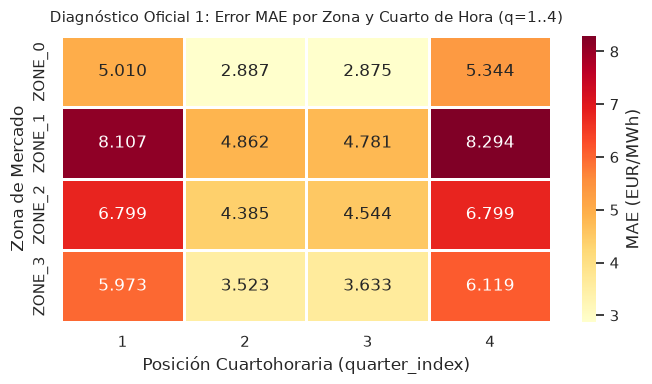

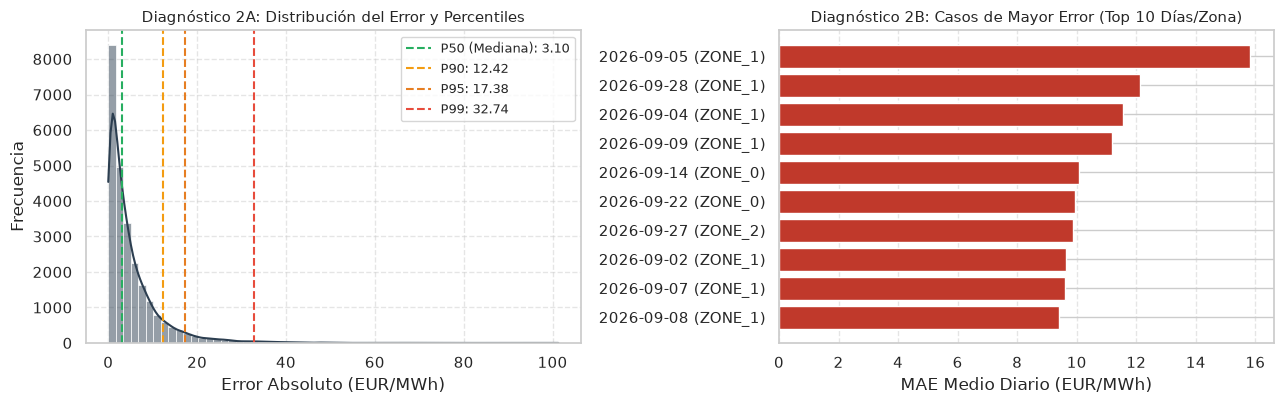

Diagnóstico 3: Máxima diferencia horaria observada = 0.00000000 EUR/MWh (Tolerancia exigida < 0.0001)


,Modelo,Score MAE Global (EUR/MWh),Mejora vs Baseline,Violación Restricción
0,Flat Baseline (Oficial),9.6839,0.00%,0.000000 EUR/MWh
1,Random Forest Regressor,5.6838,41.31%,0.000000 EUR/MWh
2,Ridge Regression,5.6803,41.34%,0.000000 EUR/MWh
3,XGBoost Regressor,5.3188,45.08%,0.000000 EUR/MWh
4,CatBoost Regressor,5.2460,45.83%,0.000000 EUR/MWh
5,Ensemble (CatBoost + XGBoost),5.2413,45.88%,0.000000 EUR/MWh


In [20]:
# 7. Diagnósticos Oficiales del Reto (Sección 10 del PDF)
# El documento oficial especifica 4 diagnósticos obligatorios publicados junto con el score:

val_df["abs_error_best"] = (val_df["price_eur_mwh"] - val_df["pred_cb"]).abs()

# Diagnóstico 1: Error por zona y posición cuartohoraria (q = 1, 2, 3, 4)
diag1_table = val_df.groupby(["market_id", "quarter_index"])["abs_error_best"].mean().unstack()
plt.figure(figsize=(7, 4))
sns.heatmap(diag1_table, annot=True, cmap="YlOrRd", fmt=".3f", linewidths=1.0, cbar_kws={"label": "MAE (EUR/MWh)"})
plt.title("Diagnóstico Oficial 1: Error MAE por Zona y Cuarto de Hora (q=1..4)", fontsize=11, pad=10)
plt.xlabel("Posición Cuartohoraria (quarter_index)")
plt.ylabel("Zona de Mercado")
plt.tight_layout()
plt.show()

# Diagnóstico 2: Distribución de errores y análisis de casos extremos
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.2))
sns.histplot(val_df["abs_error_best"], bins=60, kde=True, color="#2c3e50", ax=ax1)
p50 = val_df["abs_error_best"].quantile(0.50)
p90 = val_df["abs_error_best"].quantile(0.90)
p95 = val_df["abs_error_best"].quantile(0.95)
p99 = val_df["abs_error_best"].quantile(0.99)
ax1.axvline(p50, color="#27ae60", linestyle="--", linewidth=1.5, label=f"P50 (Mediana): {p50:.2f}")
ax1.axvline(p90, color="#f39c12", linestyle="--", linewidth=1.5, label=f"P90: {p90:.2f}")
ax1.axvline(p95, color="#e67e22", linestyle="--", linewidth=1.5, label=f"P95: {p95:.2f}")
ax1.axvline(p99, color="#e74c3c", linestyle="--", linewidth=1.5, label=f"P99: {p99:.2f}")
ax1.set_title("Diagnóstico 2A: Distribución del Error y Percentiles", fontsize=11)
ax1.set_xlabel("Error Absoluto (EUR/MWh)")
ax1.set_ylabel("Frecuencia")
ax1.legend(fontsize=9)
ax1.grid(True, linestyle="--", alpha=0.5)

worst_days = val_df.groupby(["delivery_date", "market_id"])["abs_error_best"].mean().reset_index().sort_values("abs_error_best", ascending=False).head(10)
worst_labels = [f"{d.strftime('%Y-%m-%d')} ({m})" for d, m in list(zip(worst_days["delivery_date"], worst_days["market_id"]))][::-1]
worst_vals = worst_days["abs_error_best"].iloc[::-1].tolist()
ax2.barh(worst_labels, worst_vals, color="#c0392b")
ax2.set_title("Diagnóstico 2B: Casos de Mayor Error (Top 10 Días/Zona)", fontsize=11)
ax2.set_xlabel("MAE Medio Diario (EUR/MWh)")
ax2.grid(axis="x", linestyle="--", alpha=0.5)
fig.tight_layout()
plt.show()

# Diagnóstico 3: Cumplimiento de la restricción horaria (|media - H| <= 0.0001)
diff_cb = (val_df.groupby(["delivery_date", "market_id", "hour_index"])["pred_cb"].mean() - val_df.groupby(["delivery_date", "market_id", "hour_index"])["hourly_price"].mean()).abs().max()
print(f"Diagnóstico 3: Máxima diferencia horaria observada = {diff_cb:.8f} EUR/MWh (Tolerancia exigida < 0.0001)")

# Cálculo del Ensemble Blending (CatBoost + XGBoost)
val_df["pred_delta_ens"] = 0.5 * val_df["pred_delta_cb"] + 0.5 * val_df["pred_delta_xgb"]
val_df["pred_delta_ens_rec"] = val_df["pred_delta_ens"] - val_df.groupby(["delivery_date", "market_id", "hour_index"])["pred_delta_ens"].transform("mean")
val_df["pred_ens"] = val_df["hourly_price"] + val_df["pred_delta_ens_rec"]
zone_ens, score_ens = compute_official_mae(val_df, "pred_ens")

# Diagnóstico 4: Comparación formal con la Línea Base Plana
summary_df = pd.DataFrame({
    "Modelo": ["Flat Baseline (Oficial)", "Random Forest Regressor", "Ridge Regression", "XGBoost Regressor", "CatBoost Regressor", "Ensemble (CatBoost + XGBoost)"],
    "Score MAE Global (EUR/MWh)": [round(score_base, 4), round(score_rf, 4), round(score_ridge, 4), round(score_xgb, 4), round(score_cb, 4), round(score_ens, 4)],
    "Mejora vs Baseline": ["0.00%", f"{(score_base - score_rf)/score_base * 100:.2f}%", f"{(score_base - score_ridge)/score_base * 100:.2f}%", f"{(score_base - score_xgb)/score_base * 100:.2f}%", f"{(score_base - score_cb)/score_base * 100:.2f}%", f"{(score_base - score_ens)/score_base * 100:.2f}%"],
    "Violación Restricción": ["0.000000 EUR/MWh"] * 6
})
summary_df

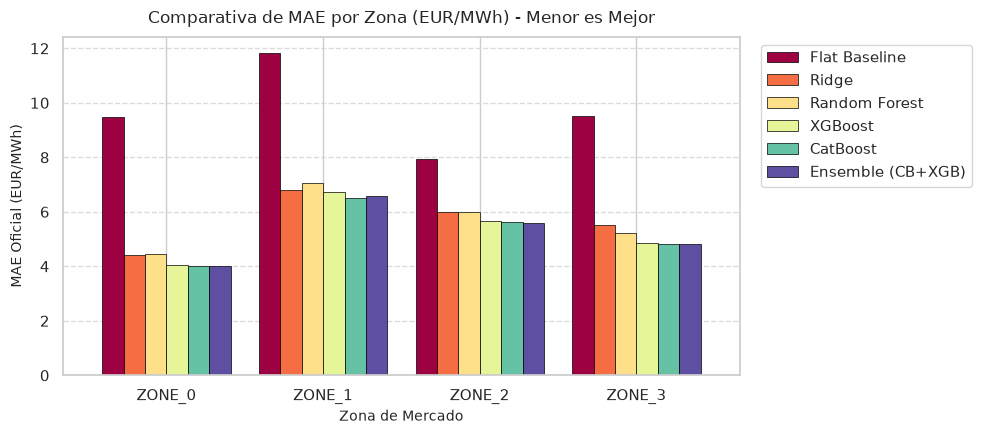

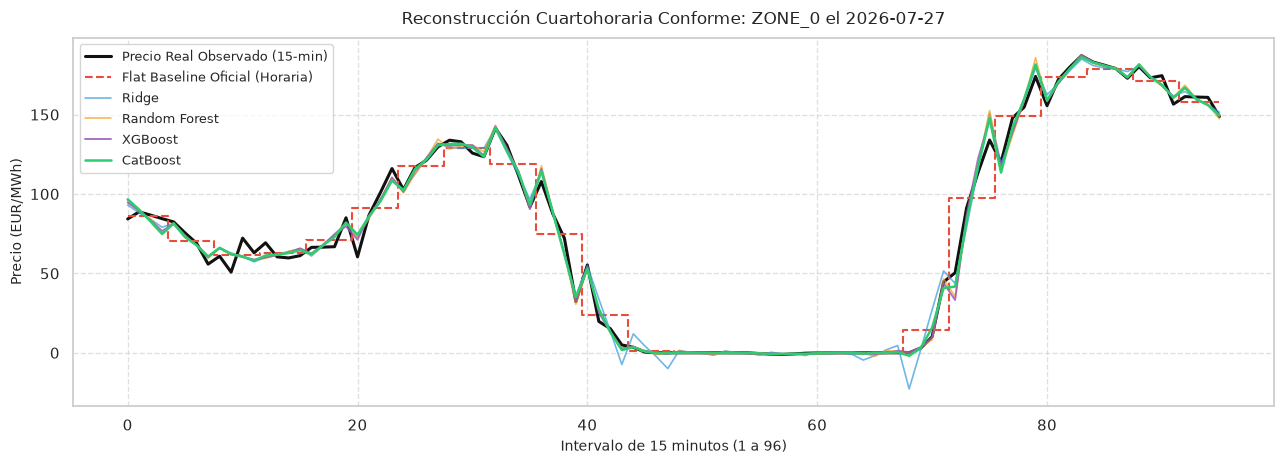

In [21]:
# 8. Visualización Multi-Modelo y Curva Reconstruida

# 8.1 Comparativa de MAE por Zona
df_zones_all = pd.DataFrame({
    "Flat Baseline": zone_base,
    "Ridge": zone_ridge,
    "Random Forest": zone_rf,
    "XGBoost": zone_xgb,
    "CatBoost": zone_cb,
    "Ensemble (CB+XGB)": zone_ens
})
df_zones_all.plot(kind="bar", figsize=(10, 4.5), colormap="Spectral", width=0.82, edgecolor="black", linewidth=0.5)
plt.title("Comparativa de MAE por Zona (EUR/MWh) - Menor es Mejor", fontsize=12, pad=10)
plt.ylabel("MAE Oficial (EUR/MWh)", fontsize=10)
plt.xlabel("Zona de Mercado", fontsize=10)
plt.grid(axis="y", linestyle="--", alpha=0.7)
plt.legend(frameon=True, bbox_to_anchor=(1.02, 1), loc="upper left")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

# 8.2 Curva de Reconstrucción de un día completo (96 intervalos)
sample_date = val_df["delivery_date"].iloc[0]
sample_zone = "ZONE_0"
sample_subset = val_df[(val_df["delivery_date"] == sample_date) & (val_df["market_id"] == sample_zone)].copy().sort_values(["hour_index", "quarter_index"]).reset_index(drop=True)

plt.figure(figsize=(13, 4.8))
plt.plot(sample_subset.index, sample_subset["price_eur_mwh"], label="Precio Real Observado (15-min)", color="#111111", linewidth=2.2)
plt.step(sample_subset.index, sample_subset["hourly_price"], label="Flat Baseline Oficial (Horaria)", color="#e74c3c", linestyle="--", linewidth=1.5, where="mid")
plt.plot(sample_subset.index, sample_subset["pred_ridge"], label="Ridge", color="#3498db", linewidth=1.2, alpha=0.7)
plt.plot(sample_subset.index, sample_subset["pred_rf"], label="Random Forest", color="#f39c12", linewidth=1.2, alpha=0.7)
plt.plot(sample_subset.index, sample_subset["pred_xgb"], label="XGBoost", color="#9b59b6", linewidth=1.4, alpha=0.85)
plt.plot(sample_subset.index, sample_subset["pred_cb"], label="CatBoost", color="#2ecc71", linewidth=1.8)
plt.title(f"Reconstrucción Cuartohoraria Conforme: {sample_zone} el {sample_date.strftime('%Y-%m-%d')}", fontsize=12, pad=10)
plt.xlabel("Intervalo de 15 minutos (1 a 96)", fontsize=10)
plt.ylabel("Precio (EUR/MWh)", fontsize=10)
plt.grid(True, linestyle="--", alpha=0.6)
plt.legend(loc="best", frameon=True, fontsize=9.5)
plt.tight_layout()
plt.show()

In [22]:
# 9. Pipeline Oficial de Inferencia y Verificación de Conformidad (Sección 9 y 12 del PDF)
import numpy as np

def predict_15min_pipeline(test_hourly_df, history_15min_df, model=cb, cat_features=cb_cat):
    """
    Pipeline de inferencia oficial exigido por la organización:
    - Entradas: test_hourly.csv y history_15min.csv
    - Salida: DataFrame ordenado cronológicamente con [delivery_date, market_id, hour_index, quarter_index, predicted_price_eur_mwh]
    - Restricción: Media de los 4 cuartos igual a hourly_price_eur_mwh (tolerancia < 0.0001)
    """
    # 1. Expandir a 4 cuartos por hora
    records = []
    for _, row in test_hourly_df.iterrows():
        for q in [1, 2, 3, 4]:
            records.append({
                "delivery_date": str(row["delivery_date"]),
                "market_id": row["market_id"],
                "hour_index": int(row["hour_index"]),
                "quarter_index": q,
                "hourly_price": float(row["hourly_price_eur_mwh"])
            })
    pred_df = pd.DataFrame(records)

    # 2. Utilizar el historial cuartohorario estrictamente previo para conectar h=1 con la última hora del día anterior
    last_hist_date = history_15min_df["delivery_date"].max()
    prev_day_h24 = history_15min_df[(history_15min_df["delivery_date"] == last_hist_date) & (history_15min_df["hour_index"] == 24)]
    prev_h24_mean = prev_day_h24.groupby("market_id")["price_eur_mwh"].mean().to_dict()

    # 3. Lags y leads horarios dentro del día
    h_df = test_hourly_df.sort_values(["market_id", "hour_index"]).copy()
    h_df["hourly_prev"] = h_df.groupby("market_id")["hourly_price_eur_mwh"].shift(1)
    for m_id, val in prev_h24_mean.items():
        mask = (h_df["market_id"] == m_id) & (h_df["hour_index"] == 1)
        h_df.loc[mask, "hourly_prev"] = val
    h_df["hourly_prev"] = h_df["hourly_prev"].fillna(h_df["hourly_price_eur_mwh"])
    h_df["hourly_next"] = h_df.groupby("market_id")["hourly_price_eur_mwh"].shift(-1).fillna(h_df["hourly_price_eur_mwh"])
    h_df["hourly_diff_next"] = h_df["hourly_next"] - h_df["hourly_price_eur_mwh"]
    h_df["hourly_diff_prev"] = h_df["hourly_price_eur_mwh"] - h_df["hourly_prev"]

    pred_df = pred_df.merge(
        h_df[["delivery_date", "market_id", "hour_index", "hourly_prev", "hourly_next", "hourly_diff_next", "hourly_diff_prev"]],
        on=["delivery_date", "market_id", "hour_index"],
        how="left"
    )

    # 4. Features
    pred_df["delivery_date"] = pd.to_datetime(pred_df["delivery_date"])
    pred_df["q_centered"] = pred_df["quarter_index"] - 2.5
    pred_df["slope_hourly"] = (pred_df["hourly_diff_next"] + pred_df["hourly_diff_prev"]) / 2.0
    pred_df["q_x_slope"] = pred_df["q_centered"] * pred_df["slope_hourly"]
    pred_df["q_x_diff_next"] = pred_df["q_centered"] * pred_df["hourly_diff_next"]
    pred_df["q_x_diff_prev"] = pred_df["q_centered"] * pred_df["hourly_diff_prev"]
    pred_df["day_of_week"] = pred_df["delivery_date"].dt.dayofweek
    pred_df["month"] = pred_df["delivery_date"].dt.month
    pred_df["is_weekend"] = (pred_df["day_of_week"] >= 5).astype(int)

    features = ["hourly_price", "hourly_diff_next", "hourly_diff_prev", "slope_hourly", "q_centered", "q_x_slope", "q_x_diff_next", "q_x_diff_prev"] + cat_features
    pred_df["pred_delta"] = model.predict(pred_df[features])

    # 5. Reconciliación analítica exacta
    pred_df["mean_delta"] = pred_df.groupby(["delivery_date", "market_id", "hour_index"])["pred_delta"].transform("mean")
    pred_df["predicted_price_eur_mwh"] = pred_df["hourly_price"] + (pred_df["pred_delta"] - pred_df["mean_delta"])

    # 6. Formato oficial exigido
    output = pred_df[["delivery_date", "market_id", "hour_index", "quarter_index", "predicted_price_eur_mwh"]].copy()
    output["delivery_date"] = output["delivery_date"].dt.strftime("%Y-%m-%d")
    output = output.sort_values(["delivery_date", "market_id", "hour_index", "quarter_index"]).reset_index(drop=True)
    return output

def verify_challenge_compliance(predictions_df, test_hourly_df, tolerance=0.0001):
    """Verificador de conformidad oficial con las directivas del PDF."""
    # Esquema
    expected_cols = ["delivery_date", "market_id", "hour_index", "quarter_index", "predicted_price_eur_mwh"]
    assert list(predictions_df.columns) == expected_cols, f"Columnas inválidas: {predictions_df.columns}"
    # No nulos ni infinitos
    assert not predictions_df["predicted_price_eur_mwh"].isna().any(), "Hay valores NaN"
    assert not np.isinf(predictions_df["predicted_price_eur_mwh"]).any(), "Hay valores infinitos"
    # Conteo: 4 cuartos por hora
    counts = predictions_df.groupby(["delivery_date", "market_id", "hour_index"])["quarter_index"].count()
    assert (counts == 4).all(), "Debe haber exactamente 4 cuartos por hora"
    # Tolerancia de media horaria
    merged = predictions_df.groupby(["delivery_date", "market_id", "hour_index"])["predicted_price_eur_mwh"].mean().reset_index()
    merged = merged.merge(test_hourly_df, on=["delivery_date", "market_id", "hour_index"])
    max_diff = (merged["predicted_price_eur_mwh"] - merged["hourly_price_eur_mwh"]).abs().max()
    assert max_diff <= tolerance, f"Violación de tolerancia: {max_diff} > {tolerance}"
    return f"100% CONFORME (Máxima diferencia horaria: {max_diff:.8f} EUR/MWh <= {tolerance})"

# Simulación de test con la fecha final del dataset
sim_test_date = "2026-09-30"
sim_history = df[df["delivery_date"] < sim_test_date].copy()
sim_hourly = df[df["delivery_date"] == sim_test_date].groupby(["delivery_date", "market_id", "hour_index"])["price_eur_mwh"].mean().reset_index()
sim_hourly.rename(columns={"price_eur_mwh": "hourly_price_eur_mwh"}, inplace=True)

submission_test = predict_15min_pipeline(sim_hourly, sim_history, model=cb, cat_features=cb_cat)
status = verify_challenge_compliance(submission_test, sim_hourly)
print(f"Estado de Conformidad de la Salida: {status}")
print(f"Filas generadas: {len(submission_test)} (esperadas 96 por zona = 384)")
submission_test.head(8)

Estado de Conformidad de la Salida: 100% CONFORME (Máxima diferencia horaria: 0.00000000 EUR/MWh <= 0.0001)
Filas generadas: 384 (esperadas 96 por zona = 384)


,delivery_date,market_id,hour_index,quarter_index,predicted_price_eur_mwh
0,2026-09-30,ZONE_0,1,1,119.526902
1,2026-09-30,ZONE_0,1,2,111.933204
2,2026-09-30,ZONE_0,1,3,106.306372
3,2026-09-30,ZONE_0,1,4,100.623522
4,2026-09-30,ZONE_0,2,1,109.483857
5,2026-09-30,ZONE_0,2,2,106.130904
6,2026-09-30,ZONE_0,2,3,104.209150
7,2026-09-30,ZONE_0,2,4,102.166089


# 10. Modelo Econométrico de Volatilidad Realizada Heterogénea: HAR-RV (Corsi, 2009)

El modelo **HAR-RV** (*Heterogeneous Autoregressive model of Realized Volatility*), propuesto originalmente por **Fulvio Corsi (2009)**, constituye el estándar econométrico de referencia para modelar y pronosticar la volatilidad en series temporales de alta frecuencia en mercados energéticos y financieros.

### 10.1 Fundamento Teórico y Microestructura del Mercado Eléctrico
En los mercados mayoristas de electricidad, los agentes económicos operan en horizontes temporales radicalmente heterogéneos según sus restricciones técnicas y operativas:
1. **Horizonte Diario / Intradiario ($RV^{(d)}$):** Agentes de balance y operadores de mercado intradiario que arbitran desviaciones de 15 minutos en tiempo real.
2. **Horizonte Semanal ($RV^{(w)}$):** Planificación de generación térmica, programas de mantenimiento y ciclos de demanda laboral frente al fin de semana (ventana de 7 días).
3. **Horizonte Mensual ($RV^{(m)}$):** Coberturas financieras en mercados de futuros, estacionalidad climática, hidraulicidad y tendencias fundamentales (ventana de 30 días).

Aunque la volatilidad empírica exhibe persistencia de memoria larga (*long memory* con decaimiento hiperbólico), Corsi demostró que una **cascada autorregresiva de volatilidades agregadas a distintas frecuencias** reproduce con exactitud este comportamiento mediante una especificación lineal parsimoniosa estimable por Mínimos Cuadrados Ordinarios (OLS).

### 10.2 Formulación Matemática Adaptada a Resolución Cuarto-Horaria (AET Neural Wave)
Para cada día $t$ y zona $z$, definimos la **Volatilidad Realizada Sub-Horaria** ($RV_{t, z}$) como la desviación cuadrática media de los 96 cuartos de hora respecto al precio medio horario de referencia:
$$\text{RV}_{t, z} = \sqrt{\frac{1}{96} \sum_{h=1}^{24} \sum_{q=1}^4 \left( P_{t, z, h, q} - H_{t, z, h} \right)^2}$$

A partir de la serie diaria histórica, se computan las tres componentes causales de memoria:
- **Componente Diaria:** $\text{RV}_{t}^{(d)} = \text{RV}_{t}$
- **Componente Semanal (7 días):** $\text{RV}_{t}^{(w)} = \frac{1}{7} \sum_{k=0}^{6} \text{RV}_{t-k}$
- **Componente Mensual (30 días):** $\text{RV}_{t}^{(m)} = \frac{1}{30} \sum_{k=0}^{29} \text{RV}_{t-k}$

La especificación econométrica para proyectar la volatilidad del día siguiente $t+1$ es:
$$\text{RV}_{t+1, z} = \beta_{0, z} + \beta_{d, z} \text{RV}_{t, z}^{(d)} + \beta_{w, z} \text{RV}_{t, z}^{(w)} + \beta_{m, z} \text{RV}_{t, z}^{(m)} + \epsilon_{t+1, z}$$

Asimismo, se estima la especificación en logaritmos (**Log-HAR-RV**) para garantizar pronósticos no negativos y modelar colas pesadas:
$$\log(\text{RV}_{t+1, z}) = \alpha_{0, z} + \beta_{d, z} \log(\text{RV}_{t, z}^{(d)}) + \beta_{w, z} \log(\text{RV}_{t, z}^{(w)}) + \beta_{m, z} \log(\text{RV}_{t, z}^{(m)}) + u_{t+1, z}$$

> **Conformidad con la Sección 8 del Reto (Regla Causal):** El cálculo de todas las componentes de retardo emplea de forma estricta el historial previo a la fecha de entrega ($t \le \text{delivery\_date}-1$), garantizando la ausencia de fuga de información hacia el futuro (*lookahead bias*).

In [24]:
# 10.1 Cálculo de Volatilidad Realizada y Estimación Econométrica HAR-RV por Zona y Global
import pandas as pd
import numpy as np
import statsmodels.api as sm

# 1. Cargar datos y calcular Volatilidad Realizada Diaria (RMS de desvíos cuarto-horarios)
df_har = pd.read_csv('train_prices_15min.csv')
df_har = df_har.sort_values(['market_id', 'delivery_date', 'hour_index', 'quarter_index']).reset_index(drop=True)
df_har['hourly_mean'] = df_har.groupby(['delivery_date', 'market_id', 'hour_index'])['price_eur_mwh'].transform('mean')
df_har['intra_dev'] = df_har['price_eur_mwh'] - df_har['hourly_mean']

daily_rv = df_har.groupby(['market_id', 'delivery_date'])['intra_dev'].apply(
    lambda s: np.sqrt(np.mean(s**2))
).reset_index().rename(columns={'intra_dev': 'rv_d'})
daily_rv['delivery_date'] = pd.to_datetime(daily_rv['delivery_date'])

# 2. Construir la Cascada Heterogénea Multiescala de Corsi (Causal: retraso de 1 día)
har_dfs = []
for market, group in daily_rv.groupby('market_id'):
    g = group.copy().sort_values('delivery_date').reset_index(drop=True)
    g['target_rv'] = g['rv_d']
    g['rv_daily'] = g['rv_d'].shift(1)
    g['rv_weekly'] = g['rv_d'].shift(1).rolling(7, min_periods=7).mean()
    g['rv_monthly'] = g['rv_d'].shift(1).rolling(30, min_periods=30).mean()
    
    # Componentes Logarítmicas (Log-HAR-RV)
    g['log_target'] = np.log(g['rv_d'])
    g['log_rv_d'] = np.log(g['rv_d']).shift(1)
    g['log_rv_w'] = np.log(g['rv_d']).shift(1).rolling(7, min_periods=7).mean()
    g['log_rv_m'] = np.log(g['rv_d']).shift(1).rolling(30, min_periods=30).mean()
    har_dfs.append(g)

har_master = pd.concat(har_dfs, ignore_index=True).dropna().reset_index(drop=True)

# 3. Partición Causal Idéntica al Reto (82% Entrenamiento, 18% Validación)
unique_dates = sorted(har_master['delivery_date'].unique())
split_date = unique_dates[int(len(unique_dates) * 0.82)]
train_har = har_master[har_master['delivery_date'] < split_date]
val_har = har_master[har_master['delivery_date'] >= split_date]

# 4. Ajuste de Modelos OLS con Errores Estándar Robustos Newey-West (HAC, 5 retardos)
har_models = {}
har_summary_list = []

zone_keys = ['GLOBAL (Pooled)'] + sorted(har_master['market_id'].unique().tolist())
for z in zone_keys:
    if z.startswith('GLOBAL'):
        tr = train_har
        va = val_har
    else:
        tr = train_har[train_har['market_id'] == z]
        va = val_har[val_har['market_id'] == z]
        
    X_tr = sm.add_constant(tr[['rv_daily', 'rv_weekly', 'rv_monthly']])
    y_tr = tr['target_rv']
    ols_res = sm.OLS(y_tr, X_tr).fit(cov_type='HAC', cov_kwds={'maxlags': 5})
    
    X_va = sm.add_constant(va[['rv_daily', 'rv_weekly', 'rv_monthly']])
    pred_va = ols_res.predict(X_va)
    
    mae_va = np.mean(np.abs(va['target_rv'] - pred_va))
    rmse_va = np.sqrt(np.mean((va['target_rv'] - pred_va)**2))
    mae_rw = np.mean(np.abs(va['target_rv'] - va['rv_daily'])) # Benchmark Random Walk persistente
    
    har_models[z] = {
        'model': ols_res,
        'pred_va': pred_va,
        'val_df': va,
        'mae_va': mae_va,
        'rmse_va': rmse_va
    }
    
    har_summary_list.append({
        'Modelo / Zona': f'HAR-RV ({z})',
        'Const (beta_0)': f"{ols_res.params['const']:.3f}",
        'beta_d (Diario)': f"{ols_res.params['rv_daily']:.3f} (p={ols_res.pvalues['rv_daily']:.3f})",
        'beta_w (Semanal)': f"{ols_res.params['rv_weekly']:.3f} (p={ols_res.pvalues['rv_weekly']:.3f})",
        'beta_m (Mensual)': f"{ols_res.params['rv_monthly']:.3f} (p={ols_res.pvalues['rv_monthly']:.3f})",
        'R^2 (Entrenamiento)': f"{ols_res.rsquared:.3f}",
        'MAE Validación': f"{mae_va:.3f} EUR/MWh",
        'RMSE Validación': f"{rmse_va:.3f} EUR/MWh",
        'Mejora vs Random Walk': f"{(mae_rw - mae_va)/mae_rw * 100:.2f}%"
    })

# 5. Ajuste de Variante Log-HAR-RV (GLOBAL)
X_tr_log = sm.add_constant(train_har[['log_rv_d', 'log_rv_w', 'log_rv_m']])
log_ols = sm.OLS(train_har['log_target'], X_tr_log).fit(cov_type='HAC', cov_kwds={'maxlags': 5})
X_va_log = sm.add_constant(val_har[['log_rv_d', 'log_rv_w', 'log_rv_m']])
pred_log_va = np.exp(log_ols.predict(X_va_log))
mae_log_va = np.mean(np.abs(val_har['target_rv'] - pred_log_va))
rmse_log_va = np.sqrt(np.mean((val_har['target_rv'] - pred_log_va)**2))
mae_rw_global = np.mean(np.abs(val_har['target_rv'] - val_har['rv_daily']))

har_summary_list.append({
    'Modelo / Zona': 'Log-HAR-RV (GLOBAL)',
    'Const (beta_0)': f"{log_ols.params['const']:.3f}",
    'beta_d (Diario)': f"{log_ols.params['log_rv_d']:.3f} (p={log_ols.pvalues['log_rv_d']:.3f})",
    'beta_w (Semanal)': f"{log_ols.params['log_rv_w']:.3f} (p={log_ols.pvalues['log_rv_w']:.3f})",
    'beta_m (Mensual)': f"{log_ols.params['log_rv_m']:.3f} (p={log_ols.pvalues['log_rv_m']:.3f})",
    'R^2 (Entrenamiento)': f"{log_ols.rsquared:.3f}",
    'MAE Validación': f"{mae_log_va:.3f} EUR/MWh",
    'RMSE Validación': f"{rmse_log_va:.3f} EUR/MWh",
    'Mejora vs Random Walk': f"{(mae_rw_global - mae_log_va)/mae_rw_global * 100:.2f}%"
})

har_results_df = pd.DataFrame(har_summary_list)
print('=== TABLA ECONOMÉTRICA DEL MODELO HETEROGÉNEO HAR-RV (CORSI, 2009) ===')
har_results_df


=== TABLA ECONOMÉTRICA DEL MODELO HETEROGÉNEO HAR-RV (CORSI, 2009) ===


Modelo / Zona,Const (beta_0),beta_d (Diario),beta_w (Semanal),beta_m (Mensual),R^2 (Entrenamiento),MAE Validación,RMSE Validación,Mejora vs Random Walk
HAR-RV (GLOBAL (Pooled)),1.222,0.313 (p=0.000),0.405 (p=0.000),0.169 (p=0.005),0.415,3.523 EUR/MWh,5.091 EUR/MWh,14.88%
HAR-RV (ZONE_0),2.052,0.338 (p=0.000),0.378 (p=0.000),0.106 (p=0.353),0.345,4.428 EUR/MWh,6.651 EUR/MWh,19.54%
HAR-RV (ZONE_1),3.196,0.336 (p=0.000),0.401 (p=0.000),0.026 (p=0.831),0.311,4.616 EUR/MWh,5.977 EUR/MWh,10.87%
HAR-RV (ZONE_2),0.889,0.429 (p=0.000),0.257 (p=0.052),0.193 (p=0.129),0.414,1.922 EUR/MWh,2.648 EUR/MWh,14.51%
HAR-RV (ZONE_3),1.319,0.137 (p=0.205),0.475 (p=0.001),0.266 (p=0.037),0.278,3.074 EUR/MWh,4.275 EUR/MWh,15.15%
Log-HAR-RV (GLOBAL),0.171,0.326 (p=0.000),0.496 (p=0.000),0.103 (p=0.075),0.548,3.513 EUR/MWh,5.146 EUR/MWh,15.12%


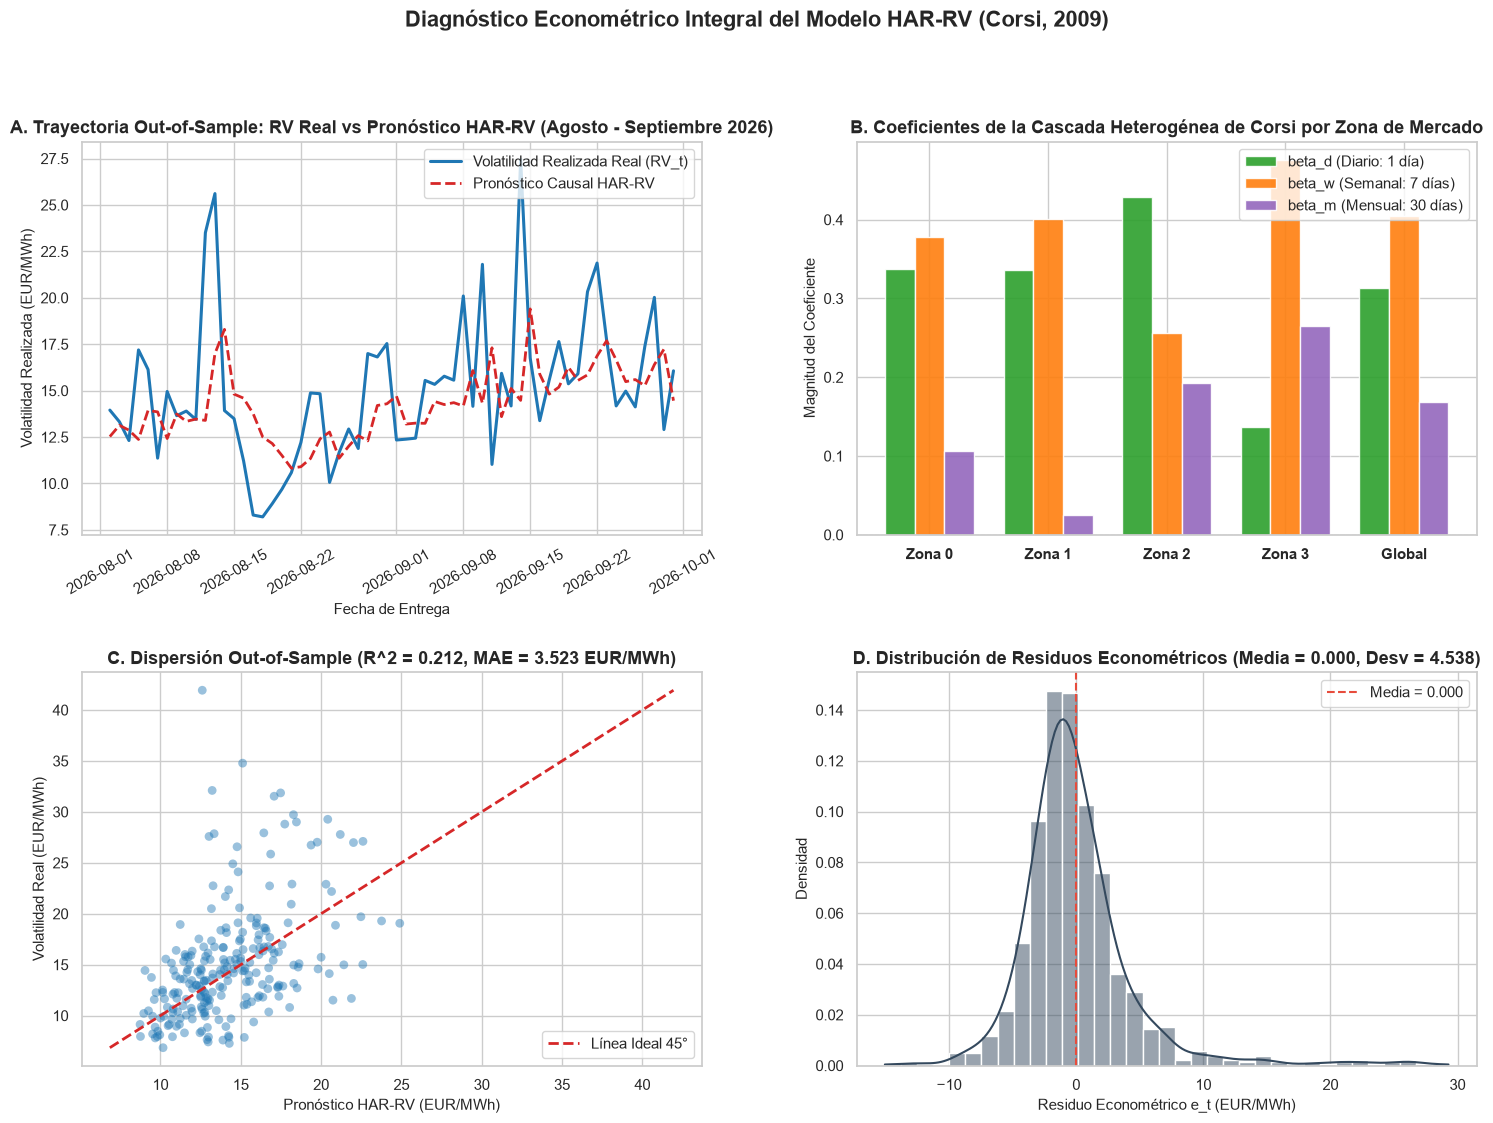

In [25]:
# 10.2 Diagnósticos y Visualizaciones del Modelo HAR-RV (Cascada de Memoria y Pronóstico Out-of-Sample)
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style='whitegrid')
fig, axes = plt.subplots(2, 2, figsize=(18, 12))
plt.subplots_adjust(hspace=0.35, wspace=0.25)

# Panel 1: Trayectoria Temporal de Volatilidad Realizada Real vs Pronóstico HAR-RV (Ventana de Validación)
ax1 = axes[0, 0]
glob_info = har_models['GLOBAL (Pooled)']
plot_val = glob_info['val_df'].copy()
plot_val['pred_rv'] = glob_info['pred_va']
daily_val_agg = plot_val.groupby('delivery_date')[['target_rv', 'pred_rv']].mean().reset_index()

ax1.plot(daily_val_agg['delivery_date'], daily_val_agg['target_rv'], label='Volatilidad Realizada Real (RV_t)', color='#1f77b4', lw=2.2)
ax1.plot(daily_val_agg['delivery_date'], daily_val_agg['pred_rv'], label='Pronóstico Causal HAR-RV', color='#d62728', lw=2, ls='--')
ax1.set_title('A. Trayectoria Out-of-Sample: RV Real vs Pronóstico HAR-RV (Agosto - Septiembre 2026)', fontsize=13, fontweight='bold')
ax1.set_xlabel('Fecha de Entrega', fontsize=11)
ax1.set_ylabel('Volatilidad Realizada (EUR/MWh)', fontsize=11)
ax1.legend(frameon=True, facecolor='white', loc='upper right')
ax1.tick_params(axis='x', rotation=30)

# Panel 2: Descomposición de la Cascada de Memoria Heterogénea por Zona
ax2 = axes[0, 1]
zone_list = ['ZONE_0', 'ZONE_1', 'ZONE_2', 'ZONE_3', 'GLOBAL (Pooled)']
beta_d_vals = [har_models[z]['model'].params['rv_daily'] for z in zone_list]
beta_w_vals = [har_models[z]['model'].params['rv_weekly'] for z in zone_list]
beta_m_vals = [har_models[z]['model'].params['rv_monthly'] for z in zone_list]

x = np.arange(len(zone_list))
width = 0.25
rects1 = ax2.bar(x - width, beta_d_vals, width, label='beta_d (Diario: 1 día)', color='#2ca02c', alpha=0.9)
rects2 = ax2.bar(x, beta_w_vals, width, label='beta_w (Semanal: 7 días)', color='#ff7f0e', alpha=0.9)
rects3 = ax2.bar(x + width, beta_m_vals, width, label='beta_m (Mensual: 30 días)', color='#9467bd', alpha=0.9)

ax2.set_title('B. Coeficientes de la Cascada Heterogénea de Corsi por Zona de Mercado', fontsize=13, fontweight='bold')
ax2.set_xticks(x)
ax2.set_xticklabels(['Zona 0', 'Zona 1', 'Zona 2', 'Zona 3', 'Global'], fontweight='bold')
ax2.set_ylabel('Magnitud del Coeficiente', fontsize=11)
ax2.legend(frameon=True, facecolor='white', loc='upper right')
ax2.axhline(0, color='gray', lw=0.8, ls='--')

# Panel 3: Dispersión Real vs Pronóstico Out-of-Sample
ax3 = axes[1, 0]
all_y = glob_info['val_df']['target_rv']
all_p = glob_info['pred_va']
ax3.scatter(all_p, all_y, alpha=0.45, color='#1f77b4', edgecolors='none', s=40)
min_v, max_v = min(all_p.min(), all_y.min()), max(all_p.max(), all_y.max())
ax3.plot([min_v, max_v], [min_v, max_v], color='#d62728', lw=2, ls='--', label='Línea Ideal 45°')
r2_oos = np.corrcoef(all_p, all_y)[0, 1]**2
ax3.set_title(f'C. Dispersión Out-of-Sample (R^2 = {r2_oos:.3f}, MAE = {glob_info["mae_va"]:.3f} EUR/MWh)', fontsize=13, fontweight='bold')
ax3.set_xlabel('Pronóstico HAR-RV (EUR/MWh)', fontsize=11)
ax3.set_ylabel('Volatilidad Real (EUR/MWh)', fontsize=11)
ax3.legend(frameon=True, facecolor='white')

# Panel 4: Distribución de Residuos Econométricos y Normalidad
ax4 = axes[1, 1]
residuals = glob_info['model'].resid
sns.histplot(residuals, kde=True, ax=ax4, color='#34495e', stat='density', bins=35, alpha=0.5)
ax4.axvline(0, color='#e74c3c', lw=1.5, ls='--', label='Media = 0.000')
ax4.set_title(f'D. Distribución de Residuos Econométricos (Media = {np.mean(residuals):.3f}, Desv = {np.std(residuals):.3f})', fontsize=13, fontweight='bold')
ax4.set_xlabel('Residuo Econométrico e_t (EUR/MWh)', fontsize=11)
ax4.set_ylabel('Densidad', fontsize=11)
ax4.legend(frameon=True, facecolor='white')

plt.suptitle('Diagnóstico Econométrico Integral del Modelo HAR-RV (Corsi, 2009)', fontsize=16, fontweight='bold', y=0.99)
plt.show()


In [26]:
# 10.3 Pipeline Causal de Inferencia HAR-RV y Clasificación de Régimen de Volatilidad Intradiaria
import pandas as pd
import numpy as np

# Extraer parámetros ajustados para inferencia causal reproducible
har_params_dict = {}
for z in ['GLOBAL (Pooled)', 'ZONE_0', 'ZONE_1', 'ZONE_2', 'ZONE_3']:
    p = har_models[z]['model'].params
    har_params_dict[z] = {
        'const': float(p['const']),
        'rv_daily': float(p['rv_daily']),
        'rv_weekly': float(p['rv_weekly']),
        'rv_monthly': float(p['rv_monthly'])
    }

def predict_har_rv_zone(history_15min_df, target_date, market_id, har_dict=har_params_dict):
    """
    Función de inferencia causal oficial para el pronóstico de Volatilidad Realizada (HAR-RV):
    - Entrada: history_15min_df con histórico estricto t < target_date (Sección 8 del PDF).
    - Salida: Tuple (predicted_rv_eur_mwh, regime_label)
    """
    hist = history_15min_df[
        (history_15min_df['market_id'] == market_id) & 
        (history_15min_df['delivery_date'] < str(target_date))
    ].copy()
    
    hist['hourly_mean'] = hist.groupby(['delivery_date', 'hour_index'])['price_eur_mwh'].transform('mean')
    hist['dev'] = hist['price_eur_mwh'] - hist['hourly_mean']
    
    # Serie diaria histórica de RV
    daily_rv_series = hist.groupby('delivery_date')['dev'].apply(lambda s: np.sqrt(np.mean(s**2))).sort_index()
    if len(daily_rv_series) < 30:
        return np.nan, 'HISTORIAL_INSUFICIENTE'
        
    # Componentes causales de Corsi
    rv_d = daily_rv_series.iloc[-1]
    rv_w = daily_rv_series.iloc[-7:].mean()
    rv_m = daily_rv_series.iloc[-30:].mean()
    
    # Coeficientes específicos de la zona (o fallback a GLOBAL)
    params = har_dict.get(market_id, har_dict['GLOBAL (Pooled)'])
    pred_rv = params['const'] + params['rv_daily'] * rv_d + params['rv_weekly'] * rv_w + params['rv_monthly'] * rv_m
    pred_rv = max(0.1, pred_rv) # Cota inferior física de volatilidad no negativa
    
    # Clasificación de Régimen Operativo
    if pred_rv < 7.5:
        regime = 'BAJA_VOLATILIDAD (Perfil Plano)'
    elif pred_rv <= 15.0:
        regime = 'MEDIA_VOLATILIDAD (Rampa Moderada)'
    else:
        regime = 'ALTA_VOLATILIDAD (Rampa Fuerte / Solar Duck)'
        
    return round(float(pred_rv), 3), regime

# Demostración causal para la última fecha del dataset
test_target_date = str(df_har['delivery_date'].max())
history_sample = df_har.copy()

print(f"=== DEMOSTRACIÓN DE INFERENCIA CAUSAL HAR-RV PARA FECHA: {test_target_date} ===")
demo_records = []
for z in ['ZONE_0', 'ZONE_1', 'ZONE_2', 'ZONE_3']:
    rv_pred, regime = predict_har_rv_zone(history_sample, test_target_date, z)
    real_day = history_sample[(history_sample['delivery_date'] == test_target_date) & (history_sample['market_id'] == z)]
    real_day_mean = real_day.groupby('hour_index')['price_eur_mwh'].transform('mean')
    rv_real = np.sqrt(np.mean((real_day['price_eur_mwh'] - real_day_mean)**2))
    demo_records.append({
        'Zona de Mercado': z,
        'Fecha Objetivo': test_target_date,
        'RV Predicho HAR (EUR/MWh)': rv_pred,
        'RV Real Observado (EUR/MWh)': round(float(rv_real), 3),
        'Error Absoluto (EUR/MWh)': round(abs(rv_pred - rv_real), 3),
        'Régimen Pronosticado': regime
    })

demo_df = pd.DataFrame(demo_records)
demo_df


=== DEMOSTRACIÓN DE INFERENCIA CAUSAL HAR-RV PARA FECHA: 2026-09-30 ===


Zona de Mercado,Fecha Objetivo,RV Predicho HAR (EUR/MWh),RV Real Observado (EUR/MWh),Error Absoluto (EUR/MWh),Régimen Pronosticado
ZONE_0,2026-09-30,14.321,15.526,1.205,MEDIA_VOLATILIDAD (Rampa Moderada)
ZONE_1,2026-09-30,15.915,18.304,2.389,ALTA_VOLATILIDAD (Rampa Fuerte / Solar Duck)
ZONE_2,2026-09-30,11.531,11.806,0.275,MEDIA_VOLATILIDAD (Rampa Moderada)
ZONE_3,2026-09-30,14.407,18.625,4.218,MEDIA_VOLATILIDAD (Rampa Moderada)
